# Lane Perception Development — Phase 2.3.2

Replay saved images through the **real preprocessing module**, retaining frame identity and timing. No camera, Gateway, serial port, lane search or control is started here. The completed preprocessing notebook remains separate and unchanged.

Live `capture_return_estimate` is an approximate monotonic time after `capture_array()` returns, not sensor exposure. Simulated replay time is an explicitly assumed timeline, independent of notebook execution speed.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import deque
import sys
import time
import platform
import matplotlib.pyplot as plt
import cv2
import numpy as np

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/utils/frame_packet.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start the notebook from SCRbrain or SCRbrain/notebooks.')
for path in (PROJECT_ROOT, PROJECT_ROOT / 'notebooks'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
from src.algorithms.LaneDetection.utils.preprocessing import PreprocessingMixin
from src.algorithms.LaneDetection.candidate_extractor import extract_row_markings
from src.algorithms.LaneDetection.boundary_builder import build_boundary_candidates
from src.algorithms.LaneDetection.ransac_boundary_builder import build_ransac_candidates
from src.algorithms.LaneDetection.fragment_extractor import extract_marking_fragments
from src.algorithms.LaneDetection.fragment_linker import link_marking_fragments
from src.utils.frame_packet import FramePacketOrder, preprocess_frame_packet, LatencyStatistics
from helpers.frame_replay import iter_replay_packets, replay_timing_sample, adapt_replay_packet
print('Replay host:', platform.platform(), sys.version.split()[0])

Replay host: Windows-11-10.0.26200-SP0 3.12.10


## Replay configuration

Use one directory/manifest per real sequence. Paths may be outside this repository; relative paths resolve below PROJECT_ROOT. `IMAGE_DIRECTORY = None` uses five in-memory demo images, creating no files. Re-running simulated replay creates a new session unless an explicit ID is supplied.

Simulated FPS is an assumption, **not the original capture rate**. Recorded mode accepts JSON or JSONL metadata and preserves its session IDs, frame IDs and capture times. Camera calibration is not performed. Optional image adaptation below can prepare non-BFMC images for the fixed camera input shape. Set `EXPECTED_FRAME_SHAPE = None` only for exploratory non-camera-sized images; those do not validate the real camera geometry.

In [2]:
TEST_IMAGE_DIRECTORY = "notebooks/II_test_images_lane_exctraction"  # Relative to PROJECT_ROOT; absolute path or None for demo.
REPLAY_MODE = 'simulated'        # 'simulated' or 'recorded'
RECORDED_METADATA_PATH = None    # JSON/JSONL file for recorded mode
ASSUMED_FPS = 5.0                # Only used in simulated mode; user assumption
REPLAY_SESSION_ID = None         # None generates a fresh simulated-session UUID
MAX_FRAMES = 20                  # None processes the entire chosen sequence
DISPLAY_LIMIT = 10                # Bound notebook figure output
EXPECTED_FRAME_SHAPE = (270, 512, 3)  # Actual camera BGR shape; None explicitly permits other sizes

def replay_path(value):
    if value is None:
        return None
    path = Path(value).expanduser()
    return path if path.is_absolute() else PROJECT_ROOT / path

## Optional Image Adaptation – Non-BFMC Images

Offline testing only. Enable to reuse the existing preprocessing notebook's proportional height resize and centered mean-color padding/cropping, targeting the previous notebook test canvas **650x270**. Optional bottom cropping then uses the same crop → proportional resize → horizontal center-crop sequence. This changes screenshot framing, not production calibration.

Disabled packets pass through untouched. Enabled packets retain their original IDs/timestamps and JPEG-encode only the prepared image for the common processing interface. Only the first original input is shown once as a reference; binary BEV outputs retain the existing DISPLAY_LIMIT. The shared normalizer's 650x270 defaults are temporarily overridden and restored within each call; do not run concurrent notebook normalization in the same kernel during this helper call.

In [3]:
USE_IMAGE_ADAPTATION = True  # Offline screenshot convenience only.
BOTTOM_CROP_ENABLE = False
BOTTOM_CROP_PX = 110
TEST_TARGET_WIDTH = 650
TEST_TARGET_HEIGHT = 270

def adapt_notebook_packet(packet):
    if not USE_IMAGE_ADAPTATION:
        return packet, None, None
    import base64
    from unittest.mock import patch
    from helpers import test_image_utils
    from src.algorithms.LaneDetection.utils.img_codec import ImgCodecMixin
    original = ImgCodecMixin()._decode_b64_jpg_to_bgr(packet['image_b64'])
    # Exact normalizer used by phase31_preprocessing.ipynb.
    with patch.multiple(test_image_utils, TEST_TARGET_WIDTH=TEST_TARGET_WIDTH,
                        TEST_TARGET_HEIGHT=TEST_TARGET_HEIGHT):
        adapted = test_image_utils.normalize_notebook_image(original)
    if BOTTOM_CROP_ENABLE:
        if type(BOTTOM_CROP_PX) is not int or not 0 <= BOTTOM_CROP_PX < TEST_TARGET_HEIGHT:
            print(f'WARNING: Offline bottom crop must be an integer in [0, {TEST_TARGET_HEIGHT}); correction skipped.')
        elif BOTTOM_CROP_PX > 0:
            cropped = adapted[:TEST_TARGET_HEIGHT - BOTTOM_CROP_PX]
            scale = TEST_TARGET_HEIGHT / cropped.shape[0]
            new_width = max(1, round(TEST_TARGET_WIDTH * scale))
            resized = cv2.resize(cropped, (new_width, TEST_TARGET_HEIGHT), interpolation=cv2.INTER_LINEAR)
            left = (new_width - TEST_TARGET_WIDTH) // 2
            adapted = resized[:, left:left + TEST_TARGET_WIDTH].copy()
    ok, jpg = cv2.imencode('.jpg', adapted)
    if not ok:
        raise ValueError('Cannot encode adapted replay image')
    return dict(packet, image_b64=base64.b64encode(jpg).decode('ascii')), original, adapted


## Phase 1 – Global Lane Marking Extraction
Binary BEV -> white-run center observations, widths and edge flags. Scans the full width; no lane identities or filtering.

### Phase 2.1 – Continuity baseline (optional)
Observations -> locally linked candidates. May split long gaps or merge ambiguous markings.

### Phase 2.2 – RANSAC baseline (optional)
Observations -> multiple quadratic-supported candidates. Curves are diagnostic hypotheses, not observed paint or metric geometry.

### Phase 2.3.1 – Individual Marking Fragments (primary)
Observations -> short-range visible fragments, retaining isolated points. Short fragments may lack valid tangents.

### Phase 2.3.2 – Fragment Linking and Boundary Reconstruction (primary)
Fragments -> deterministic, unlabeled chains with explicit gaps. Ambiguity, crossing and fit checks reject connections without discarding observations.

Run the configuration cell below, then processing and cached visualizations in order. Baselines are opt-in; the optional linker baseline uses function defaults rather than the hybrid LINK_* values. All geometric settings are provisional pixel-space values. Debugging records decisions only and does not change linking.


In [4]:
# Phase 1: global row-scan observations
ROW_SCAN_STEP = 5
SHOW_ROW_SCAN_OVERLAY = True
SHOW_SCAN_ROWS = False

# Phase 2.1: optional continuity baseline
RUN_CONTINUITY_BASELINE = False      # Original point-to-point linking comparison
MAX_LINK_GAP_ROWS = 16          # Maximum endpoint separation in scan strides (80 px at step 5).
MAX_HORIZONTAL_JUMP_PX = 12    # Per-stride displacement and prediction-error limit.
MAX_DIRECTION_CHANGE_DEG = 25  # Maximum change from the local direction.
MIN_CANDIDATE_POINTS = 4       # Shorter chains remain unassigned, not deleted from raw evidence.
MAX_WIDTH_RATIO = 3.0         # Maximum relative width change; no absolute width rejection.

# Phase 2.2: optional RANSAC baseline
RUN_RANSAC = True                   # Phase 2.2: RANSAC-based boundary detection comparison
RANSAC_MAX_ITERATIONS = 60#      # Bounded hypothesis attempts per candidate search.
RANSAC_INLIER_THRESHOLD_PX = 3.0 # Maximum horizontal residual in pixels.
RANSAC_MIN_INLIERS = 6           # Minimum distinct supporting scan rows.
RANSAC_MIN_Y_SPAN_PX = 60.0      # Minimum longitudinal support in pixels.
RANSAC_MAX_CANDIDATES = 4        # Per-frame extraction cap, not a target count.
RANSAC_RANDOM_SEED = 42          # Reproducible call-local sampling.
SHOW_RANSAC_MODEL = True        # Dashed diagnostic model; dots remain real evidence.
#to reduce computational power
# max_iterations = 60     # Previously 150
# max_candidates = 4      # Previously 8
# inlier_threshold_px = 3.0
# min_inliers = 6
# min_y_span_px = 60.0
#                           Optimization strategies:
# Early termination: Stop testing hypotheses once a sufficiently strong model is found, provided quality criteria are satisfied.
# Selective refinement: Perform quick preliminary scoring, then refine only the most promising models.
# More efficient numerical operations: Reduce the many small NumPy allocations and linear algebra calls.
# Guided sampling: Prefer observations from geometrically compatible regions instead of sampling randomly across the entire image.
# Fragment-level RANSAC: Use our Phase 2.3.1 fragments to generate hypotheses rather than individual points.

# Phase 2.3.1: visible marking fragments (primary)
FRAGMENT_MAX_GAP_ROWS = 2              # Maximum endpoint separation: 10 px at scan stride 5.
FRAGMENT_MAX_HORIZONTAL_JUMP_PX = 6    # Stricter per-stride displacement/prediction-error limit.
FRAGMENT_MAX_DIRECTION_CHANGE_DEG = 25 # Maximum local direction change.
FRAGMENT_MAX_WIDTH_RATIO = 3.0         # Relative width gate; no absolute width rejection.

# Phase 2.3.2: deterministic fragment linking (primary)
RUN_FRAGMENT_LINKER_BASELINE = False # Phase 2.3.2: Original linker version before refinements
LINK_MAX_GAP_PX = 140.0              # Maximum longitudinal endpoint separation in pixels.
LINK_LATERAL_TOLERANCE_PX = 7.0      # Base lateral prediction tolerance.
LINK_TANGENT_UNCERTAINTY_DEG = 10.0   # Gap-dependent tolerance growth for supported tangents.
LINK_MAX_DIRECTION_CHANGE_DEG = 28.0 # Tangent/chord and validation direction limit.
LINK_MAX_WIDTH_RATIO = 2.5          # Maximum relative typical-width change.
LINK_SHORT_MAX_GAP_PX = 20.0        # Maximum gap for weaker/missing-tangent pairs.
LINK_MIN_STRONG_POINTS = 3          # Supporting points per fragment required for long links.
LINK_CHAIN_MAX_RESIDUAL_PX = 5.0    # Maximum normalized-fit validation error in pixels.
LINK_AMBIGUITY_MARGIN = 0.02        # Near-equal pair costs leave the endpoint unlinked.
SHOW_FRAGMENT_LINKS = True         # Dashed inferred endpoint associations, never observed paint.

DEBUG_FRAGMENT_LINKING = False   # Optional decision tracing; no collection when disabled.

# Phase 2.3.2: diagnostic display selection
DEBUG_FRAME_IDS = None  # None = cached displayed frames; e.g. [0, 16] narrows the report.
DEBUG_MAX_REJECTED_PAIRS_PER_FRAME = 6  # All accepted links are always shown.


## Process packets and inspect metadata

The reusable `preprocess_frame_packet()` decodes and calls `preprocess_frame_bgr()`; timestamps stay outside the image algorithm. The latest result, bounded summaries/timing samples, and references for up to DISPLAY_LIMIT displayed frames are retained for the separate Phase 2 visualization. Frames load in natural numeric order in simulated mode; recorded mode follows manifest order. Capture-time differences are compared only within the same session.

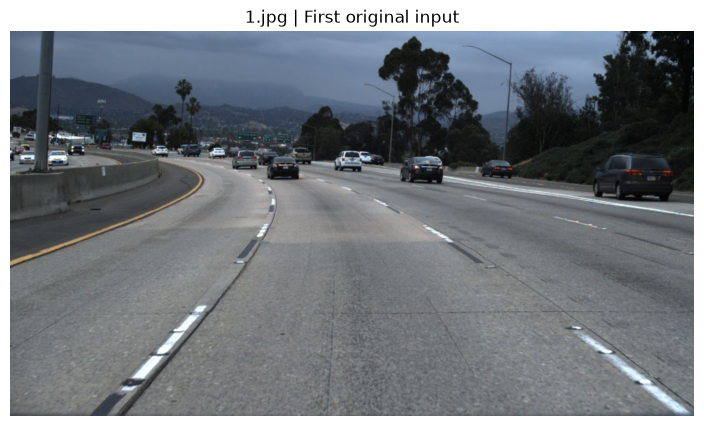

Frame 0 | scanned rows: 80 | observations: 63 | rows with observations: 42
  ransac: 2 candidates | 41.557 ms
  Visible fragments: 17 | 0.379 ms | F0=2 observations, F1=6 observations, F2=2 observations, F3=9 observations, F4=1 observations, F5=2 observations, F6=6 observations, F7=1 observations, F8=1 observations, F9=1 observations, F10=6 observations, F11=7 observations, F12=1 observations, F13=3 observations, F14=9 observations, F15=5 observations, F16=1 observations
  Fragment linking: 17 fragments -> 10 candidates | accepted links=7 | 0.976 ms


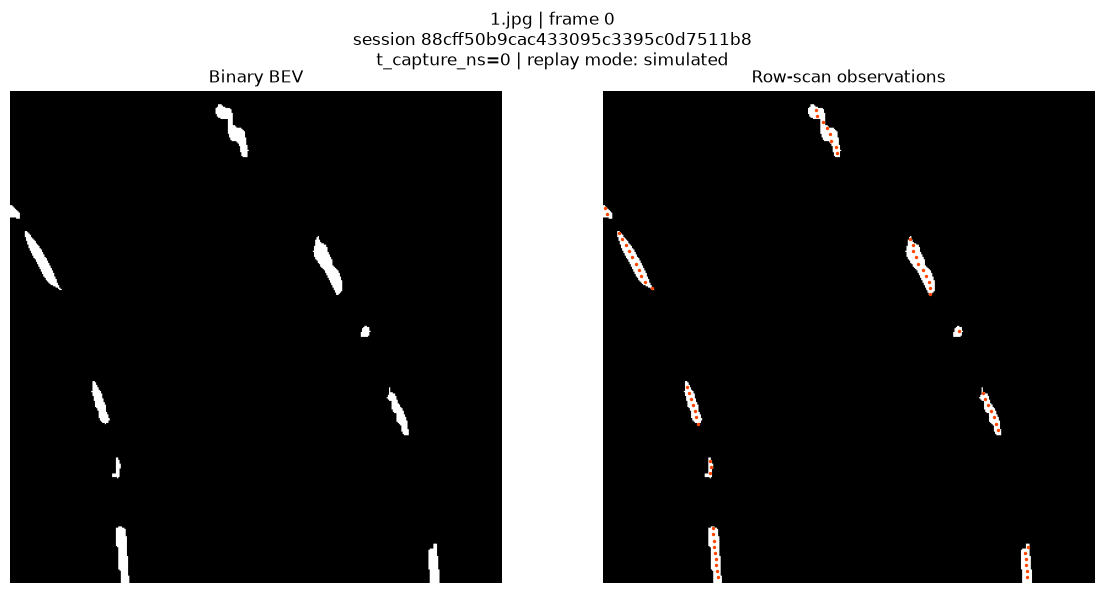

Frame 1 | scanned rows: 80 | observations: 55 | rows with observations: 37
  ransac: 2 candidates | 28.595 ms
  Visible fragments: 10 | 0.284 ms | F0=7 observations, F1=1 observations, F2=9 observations, F3=9 observations, F4=1 observations, F5=7 observations, F6=7 observations, F7=4 observations, F8=6 observations, F9=4 observations
  Fragment linking: 10 fragments -> 6 candidates | accepted links=4 | 0.540 ms


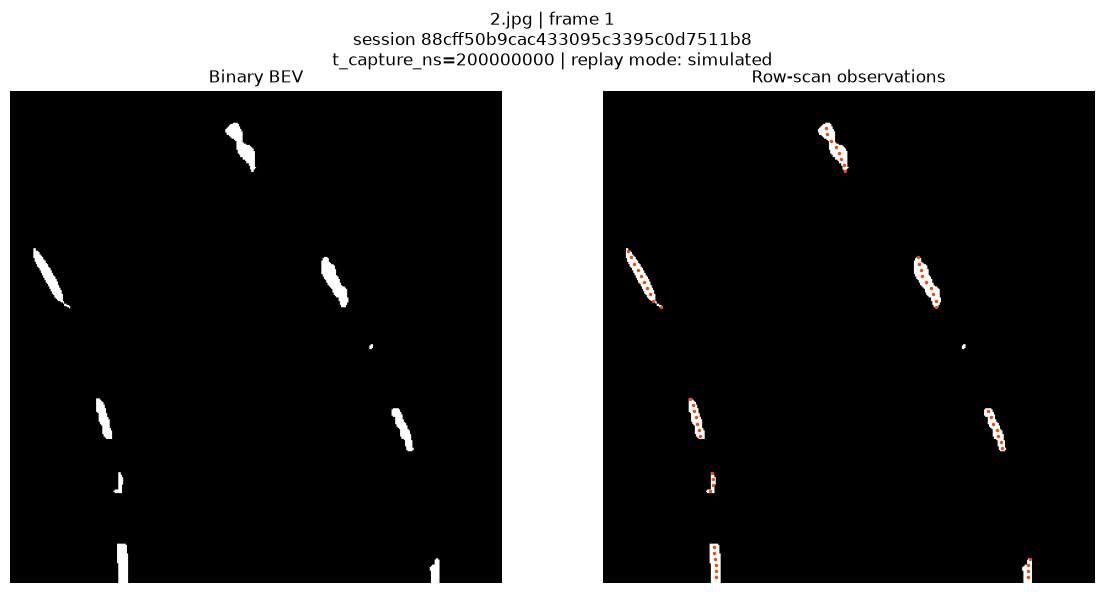

Frame 2 | scanned rows: 80 | observations: 51 | rows with observations: 37
  ransac: 3 candidates | 28.312 ms
  Visible fragments: 12 | 0.288 ms | F0=1 observations, F1=5 observations, F2=1 observations, F3=3 observations, F4=8 observations, F5=8 observations, F6=7 observations, F7=1 observations, F8=7 observations, F9=6 observations, F10=3 observations, F11=1 observations
  Fragment linking: 12 fragments -> 9 candidates | accepted links=3 | 0.446 ms


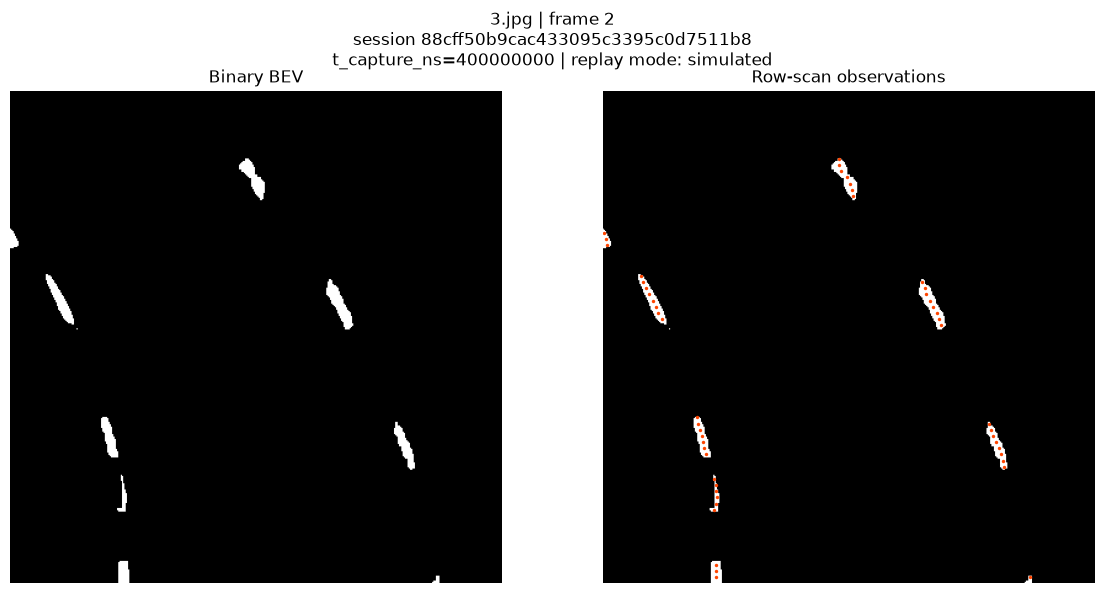

Frame 3 | scanned rows: 80 | observations: 52 | rows with observations: 38
  ransac: 2 candidates | 22.214 ms
  Visible fragments: 13 | 0.289 ms | F0=1 observations, F1=6 observations, F2=7 observations, F3=1 observations, F4=7 observations, F5=1 observations, F6=6 observations, F7=1 observations, F8=1 observations, F9=7 observations, F10=7 observations, F11=6 observations, F12=1 observations
  Fragment linking: 13 fragments -> 10 candidates | accepted links=3 | 0.442 ms


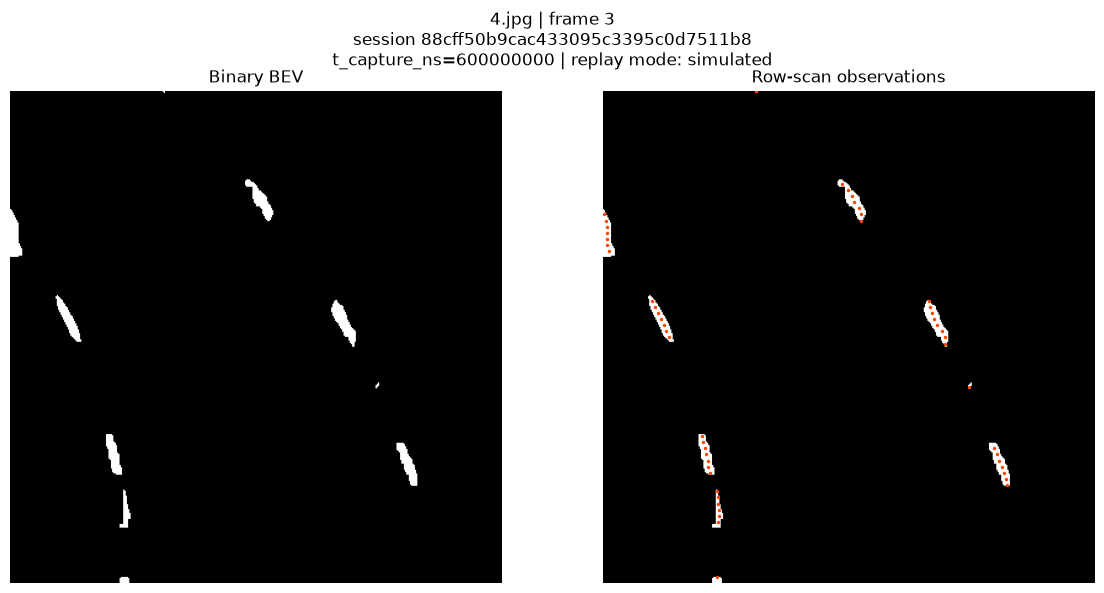

Frame 4 | scanned rows: 80 | observations: 58 | rows with observations: 38
  ransac: 2 candidates | 23.055 ms
  Visible fragments: 14 | 0.340 ms | F0=1 observations, F1=4 observations, F2=1 observations, F3=5 observations, F4=6 observations, F5=1 observations, F6=8 observations, F7=7 observations, F8=1 observations, F9=1 observations, F10=7 observations, F11=8 observations, F12=7 observations, F13=1 observations
  Fragment linking: 14 fragments -> 10 candidates | accepted links=4 | 0.642 ms


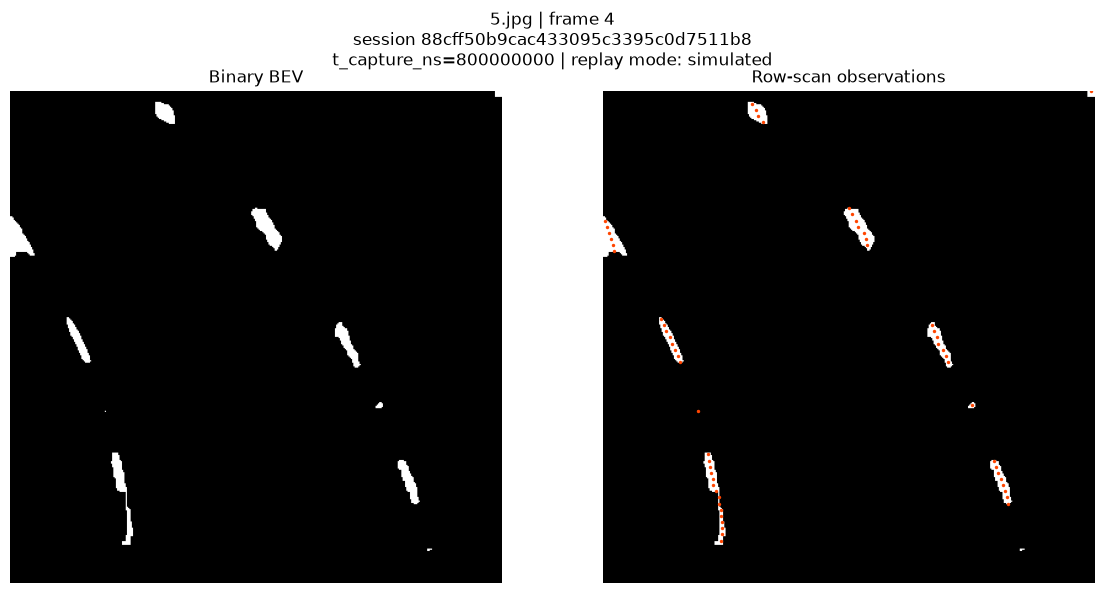

Frame 5 | scanned rows: 80 | observations: 65 | rows with observations: 42
  ransac: 2 candidates | 30.685 ms
  Visible fragments: 17 | 0.352 ms | F0=3 observations, F1=3 observations, F2=5 observations, F3=1 observations, F4=1 observations, F5=8 observations, F6=2 observations, F7=4 observations, F8=6 observations, F9=1 observations, F10=6 observations, F11=1 observations, F12=6 observations, F13=1 observations, F14=7 observations, F15=9 observations, F16=1 observations
  Fragment linking: 17 fragments -> 13 candidates | accepted links=4 | 0.628 ms


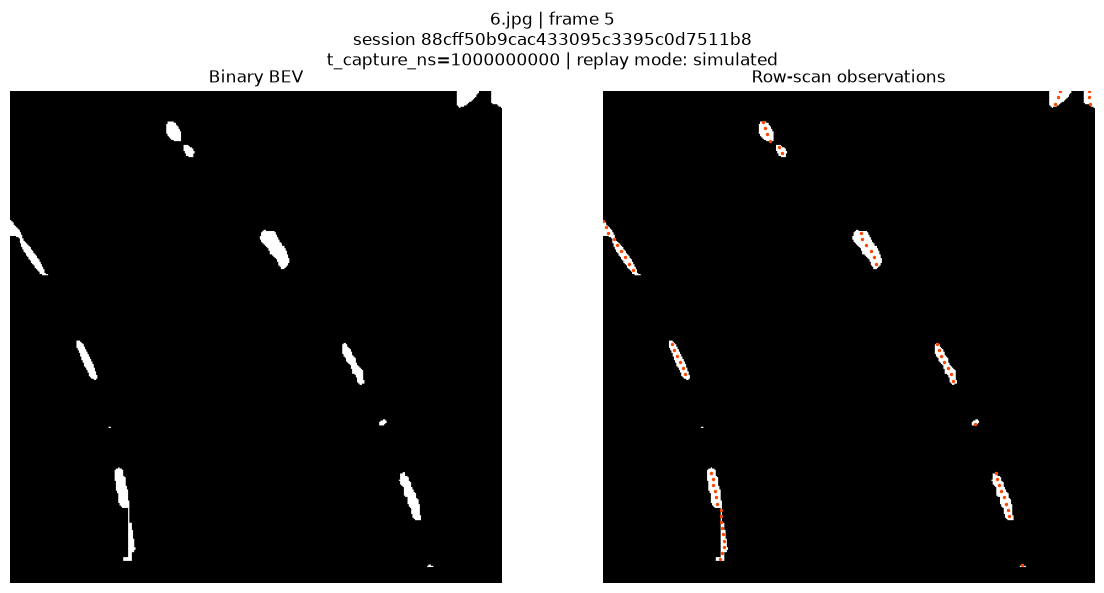

Frame 6 | scanned rows: 80 | observations: 67 | rows with observations: 45
  ransac: 2 candidates | 24.309 ms
  Visible fragments: 16 | 0.504 ms | F0=1 observations, F1=5 observations, F2=3 observations, F3=4 observations, F4=1 observations, F5=3 observations, F6=5 observations, F7=6 observations, F8=1 observations, F9=6 observations, F10=6 observations, F11=1 observations, F12=1 observations, F13=7 observations, F14=8 observations, F15=9 observations
  Fragment linking: 16 fragments -> 11 candidates | accepted links=5 | 1.022 ms


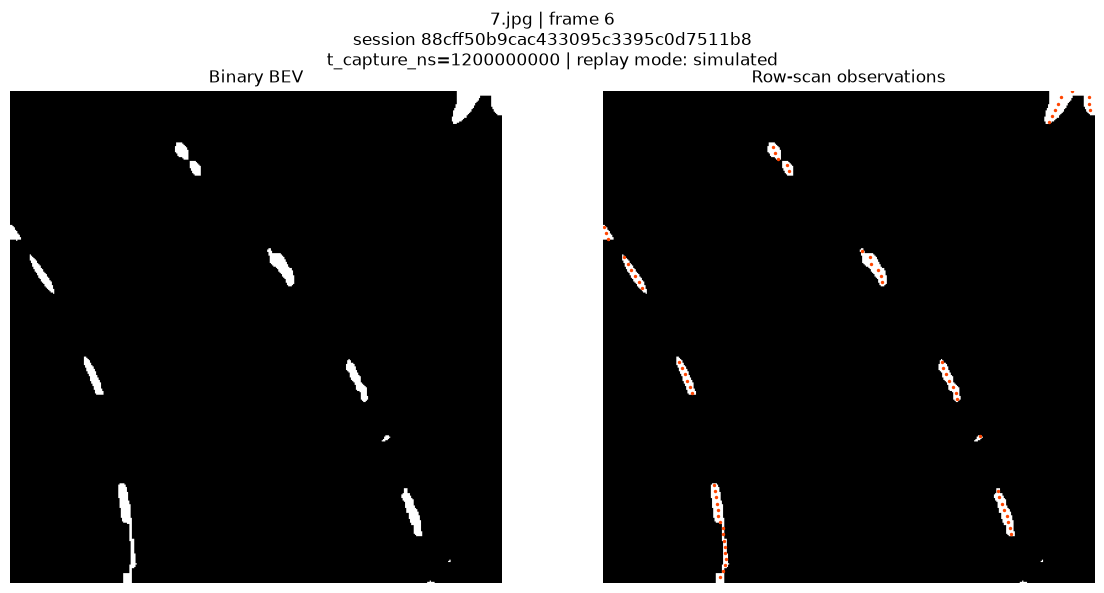

Frame 7 | scanned rows: 80 | observations: 69 | rows with observations: 45
  ransac: 2 candidates | 23.875 ms
  Visible fragments: 16 | 0.365 ms | F0=1 observations, F1=4 observations, F2=3 observations, F3=6 observations, F4=1 observations, F5=2 observations, F6=7 observations, F7=6 observations, F8=7 observations, F9=7 observations, F10=1 observations, F11=1 observations, F12=7 observations, F13=8 observations, F14=7 observations, F15=1 observations
  Fragment linking: 16 fragments -> 12 candidates | accepted links=4 | 0.571 ms


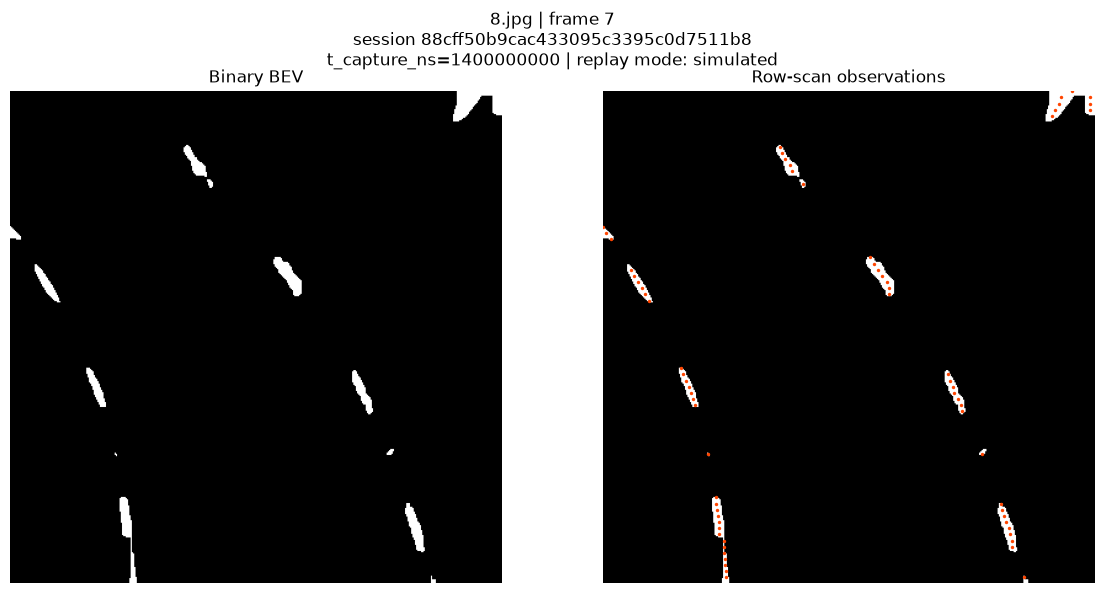

Frame 8 | scanned rows: 80 | observations: 64 | rows with observations: 43
  ransac: 2 candidates | 25.445 ms
  Visible fragments: 18 | 0.360 ms | F0=2 observations, F1=3 observations, F2=1 observations, F3=4 observations, F4=1 observations, F5=1 observations, F6=3 observations, F7=6 observations, F8=1 observations, F9=6 observations, F10=1 observations, F11=1 observations, F12=7 observations, F13=6 observations, F14=1 observations, F15=7 observations, F16=8 observations, F17=5 observations
  Fragment linking: 18 fragments -> 12 candidates | accepted links=6 | 0.790 ms


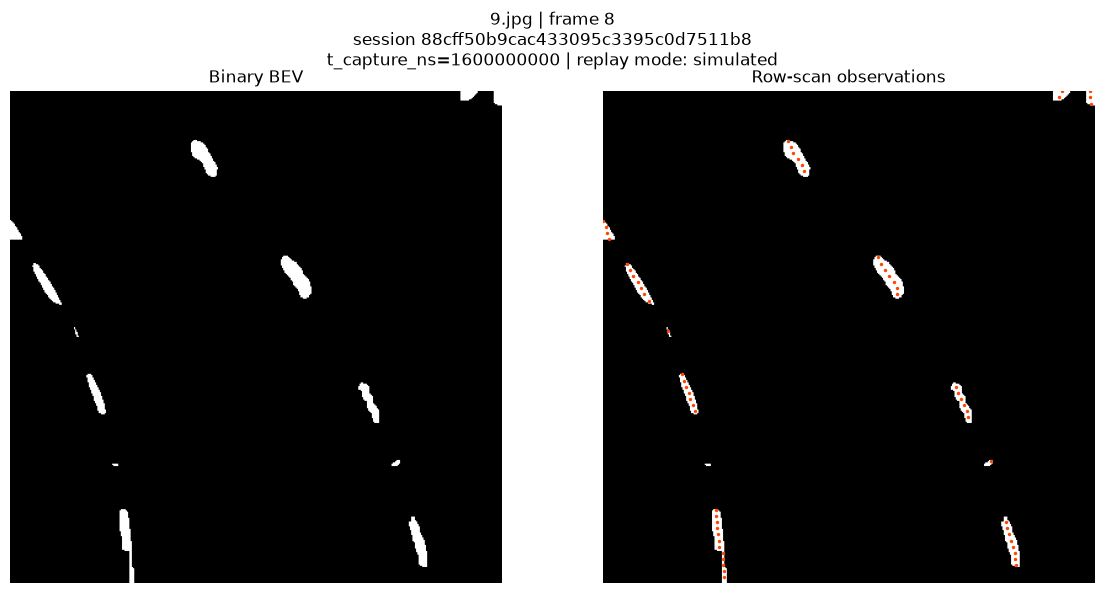

Frame 9 | scanned rows: 80 | observations: 63 | rows with observations: 40
  ransac: 2 candidates | 24.744 ms
  Visible fragments: 18 | 0.365 ms | F0=6 observations, F1=1 observations, F2=1 observations, F3=1 observations, F4=3 observations, F5=7 observations, F6=1 observations, F7=7 observations, F8=1 observations, F9=2 observations, F10=7 observations, F11=1 observations, F12=7 observations, F13=1 observations, F14=7 observations, F15=1 observations, F16=7 observations, F17=2 observations
  Fragment linking: 18 fragments -> 14 candidates | accepted links=4 | 0.761 ms


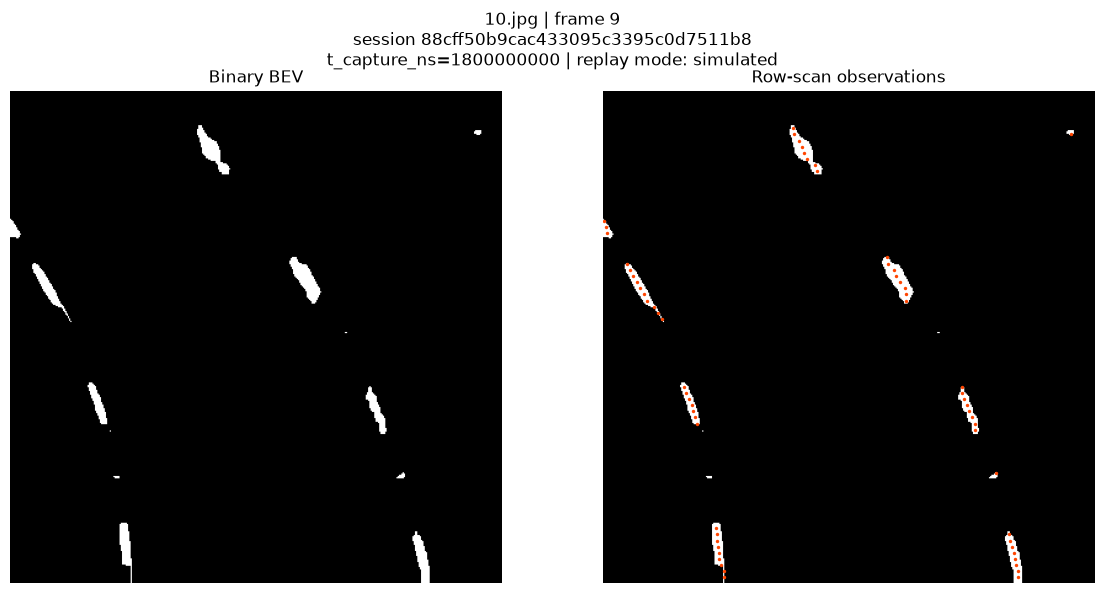

Frame 10 | scanned rows: 80 | observations: 61 | rows with observations: 41
  ransac: 2 candidates | 26.619 ms
  Visible fragments: 15 | 0.351 ms | F0=2 observations, F1=6 observations, F2=1 observations, F3=4 observations, F4=9 observations, F5=5 observations, F6=1 observations, F7=2 observations, F8=1 observations, F9=1 observations, F10=7 observations, F11=8 observations, F12=1 observations, F13=7 observations, F14=6 observations
  Fragment linking: 15 fragments -> 10 candidates | accepted links=5 | 0.641 ms
Frame 11 | scanned rows: 80 | observations: 57 | rows with observations: 39
  ransac: 2 candidates | 26.297 ms
  Visible fragments: 14 | 0.359 ms | F0=3 observations, F1=5 observations, F2=1 observations, F3=1 observations, F4=3 observations, F5=8 observations, F6=9 observations, F7=1 observations, F8=1 observations, F9=8 observations, F10=1 observations, F11=8 observations, F12=5 observations, F13=3 observations
  Fragment linking: 14 fragments -> 9 candidates | accepted links=

In [5]:
processor = PreprocessingMixin()
ordering = FramePacketOrder()
timing = LatencyStatistics()
recent_metadata = deque(maxlen=20)
candidate_comparison = deque(maxlen=200)  # Bounded development-only comparison window.
fragment_diagnostics = deque(maxlen=200)  # Bounded development-only fragment timings.
latest_result = None
display_frames = []  # References for the separate Phase 2 display, bounded by DISPLAY_LIMIT.
previous_session = previous_capture = None
processed = 0
packets = iter_replay_packets(
    replay_path(TEST_IMAGE_DIRECTORY), mode=REPLAY_MODE, assumed_fps=ASSUMED_FPS,
    metadata_path=replay_path(RECORDED_METADATA_PATH), session_id=REPLAY_SESSION_ID,
    max_frames=MAX_FRAMES)
for packet in packets:
    packet = ordering.accept(packet)
    packet, original_input, adapted_input = adapt_notebook_packet(packet)
    if processed == 0:
        if original_input is None:
            from src.algorithms.LaneDetection.utils.img_codec import ImgCodecMixin
            original_input = ImgCodecMixin()._decode_b64_jpg_to_bgr(packet['image_b64'])
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.imshow(cv2.cvtColor(original_input, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{packet.get('image_name', 'frame')} | First original input")
        ax.axis('off')
        plt.show()
        plt.close(fig)
    result = preprocess_frame_packet(packet, processor, expected_frame_shape=((TEST_TARGET_HEIGHT, TEST_TARGET_WIDTH, 3) if USE_IMAGE_ADAPTATION else EXPECTED_FRAME_SHAPE))
    binary_bev = result['binary_bev']
    observations = extract_row_markings(binary_bev, row_step=ROW_SCAN_STEP)
    candidates, ransac_candidates = [], []
    continuity_ms = ransac_ms = None
    baseline_results = {}
    if RUN_CONTINUITY_BASELINE:
        builder_start_ns = time.perf_counter_ns()
        candidates = build_boundary_candidates(
            observations, row_step=ROW_SCAN_STEP,
            max_link_gap_rows=MAX_LINK_GAP_ROWS,
            max_horizontal_jump_px=MAX_HORIZONTAL_JUMP_PX,
            max_direction_change_deg=MAX_DIRECTION_CHANGE_DEG,
            min_candidate_points=MIN_CANDIDATE_POINTS, max_width_ratio=MAX_WIDTH_RATIO)
        continuity_ms = (time.perf_counter_ns() - builder_start_ns) / 1_000_000
    if RUN_RANSAC:
        builder_start_ns = time.perf_counter_ns()
        ransac_candidates = build_ransac_candidates(
            observations, row_step=ROW_SCAN_STEP, max_iterations=RANSAC_MAX_ITERATIONS,
            inlier_threshold_px=RANSAC_INLIER_THRESHOLD_PX, min_inliers=RANSAC_MIN_INLIERS,
            min_y_span_px=RANSAC_MIN_Y_SPAN_PX, max_candidates=RANSAC_MAX_CANDIDATES,
            random_seed=RANSAC_RANDOM_SEED)
        ransac_ms = (time.perf_counter_ns() - builder_start_ns) / 1_000_000
    fragment_start_ns = time.perf_counter_ns()
    fragments = extract_marking_fragments(
        observations, row_step=ROW_SCAN_STEP, max_gap_rows=FRAGMENT_MAX_GAP_ROWS,
        max_horizontal_jump_px=FRAGMENT_MAX_HORIZONTAL_JUMP_PX,
        max_direction_change_deg=FRAGMENT_MAX_DIRECTION_CHANGE_DEG,
        max_width_ratio=FRAGMENT_MAX_WIDTH_RATIO)
    fragment_ms = (time.perf_counter_ns() - fragment_start_ns) / 1_000_000
    fragment_link_debug = [] if DEBUG_FRAGMENT_LINKING and processed < DISPLAY_LIMIT else None
    link_start_ns = time.perf_counter_ns()
    linked_candidates = link_marking_fragments(
        fragments, row_step=ROW_SCAN_STEP, max_gap_px=LINK_MAX_GAP_PX,
        lateral_tolerance_px=LINK_LATERAL_TOLERANCE_PX,
        tangent_uncertainty_deg=LINK_TANGENT_UNCERTAINTY_DEG,
        max_direction_change_deg=LINK_MAX_DIRECTION_CHANGE_DEG,
        max_width_ratio=LINK_MAX_WIDTH_RATIO, short_max_gap_px=LINK_SHORT_MAX_GAP_PX,
        min_strong_points=LINK_MIN_STRONG_POINTS,
        chain_max_residual_px=LINK_CHAIN_MAX_RESIDUAL_PX, ambiguity_margin=LINK_AMBIGUITY_MARGIN,
        diagnostics=fragment_link_debug)
    fragment_linking_ms = (time.perf_counter_ns() - link_start_ns) / 1_000_000
    accepted_link_count = sum(len(candidate['links']) for candidate in linked_candidates)
    fragment_diagnostics.append(dict(frame_id=result['frame_id'], observations=len(observations),
                                    fragment_count=len(fragments), fragment_ms=fragment_ms))
    ransac_assigned = {id(point) for candidate in ransac_candidates for point in candidate['observations']}
    ransac_unassigned = [point for point in observations if id(point) not in ransac_assigned]
    assigned = {id(point) for candidate in candidates for point in candidate['observations']}
    unassigned = [point for point in observations if id(point) not in assigned]
    if RUN_CONTINUITY_BASELINE:
        baseline_results['continuity'] = dict(candidates=candidates, unassigned=unassigned, ms=continuity_ms)
    if RUN_RANSAC:
        baseline_results['ransac'] = dict(candidates=ransac_candidates, unassigned=ransac_unassigned, ms=ransac_ms)
    if RUN_FRAGMENT_LINKER_BASELINE:
        baseline_start_ns = time.perf_counter_ns()
        default_link_candidates = link_marking_fragments(fragments, row_step=ROW_SCAN_STEP)
        default_link_ms = (time.perf_counter_ns() - baseline_start_ns) / 1_000_000
        baseline_results['fragment_linker_baseline'] = dict(candidates=default_link_candidates, unassigned=[], ms=default_link_ms)
    comparison_row = dict(
        frame_id=result['frame_id'], observations=len(observations),
        fragment_linking_ms=fragment_linking_ms, fragment_linking_candidates=len(linked_candidates),
        fragment_linking_assigned=sum(candidate['point_count'] for candidate in linked_candidates),
        fragments=len(fragments), accepted_links=accepted_link_count)
    for method, baseline_result in baseline_results.items():
        comparison_row.update({f'{method}_ms': baseline_result['ms'],
                               f'{method}_candidates': len(baseline_result['candidates']),
                               f'{method}_assigned': sum(c['point_count'] for c in baseline_result['candidates'])})
    candidate_comparison.append(comparison_row)
    scanned_rows = len(range(0, binary_bev.shape[0], ROW_SCAN_STEP))
    rows_with_observations = len({obs['y'] for obs in observations})
    print(f"Frame {result['frame_id']} | scanned rows: {scanned_rows} | "
          f"observations: {len(observations)} | rows with observations: {rows_with_observations}")
    for method, baseline_result in baseline_results.items():
        print(f"  {method}: {len(baseline_result['candidates'])} candidates | {baseline_result['ms']:.3f} ms")
    print(f"  Visible fragments: {len(fragments)} | {fragment_ms:.3f} ms | " +
          ', '.join(f"F{fragment['fragment_id']}={fragment['point_count']} observations" for fragment in fragments))
    print(f"  Fragment linking: {len(fragments)} fragments -> {len(linked_candidates)} candidates | "
          f"accepted links={accepted_link_count} | {fragment_linking_ms:.3f} ms")
    timing.add(replay_timing_sample(result))
    capture_delta_ns = (result['t_capture_ns'] - previous_capture
                        if result['session_id'] == previous_session else None)
    previous_session, previous_capture = result['session_id'], result['t_capture_ns']
    recent_metadata.append(dict(session_id=result['session_id'], frame_id=result['frame_id'],
                                t_capture_ns=result['t_capture_ns'], replay_mode=REPLAY_MODE,
                                capture_delta_ns=capture_delta_ns))
    latest_result = result
    if processed < DISPLAY_LIMIT:
        panel_count = 2 if SHOW_ROW_SCAN_OVERLAY else 1
        fig, axes = plt.subplots(1, panel_count, figsize=(6 * panel_count, 6), squeeze=False)
        plain_ax = axes[0, 0]
        overlay_ax = axes[0, 1] if SHOW_ROW_SCAN_OVERLAY else None
        plain_ax.imshow(binary_bev, cmap='gray', vmin=0, vmax=1)
        plain_ax.set_title('Binary BEV')
        plain_ax.axis('off')
        if overlay_ax is not None:
            overlay_ax.imshow(binary_bev, cmap='gray', vmin=0, vmax=1)
            if SHOW_SCAN_ROWS:
                for y in range(0, binary_bev.shape[0], ROW_SCAN_STEP):
                    overlay_ax.axhline(y, color='cyan', linewidth=0.3, alpha=0.3)
            if observations:
                overlay_ax.scatter([obs['x'] for obs in observations],
                                   [obs['y'] for obs in observations],
                                   s=6, c='orangered', linewidths=0)
            overlay_ax.set_title('Row-scan observations')
            overlay_ax.axis('off')
        metadata_title = (f"{packet.get('image_name', 'frame')} | frame {result['frame_id']}\n"
                     f"session {result['session_id']}\n"
                     f"t_capture_ns={result['t_capture_ns']} | replay mode: {REPLAY_MODE}")
        display_frames.append(dict(
            binary_bev=binary_bev, candidates=candidates, ransac_candidates=ransac_candidates,
            unassigned=unassigned, ransac_unassigned=ransac_unassigned, fragments=fragments,
            metadata_title=metadata_title, linked_candidates=linked_candidates, baseline_results=baseline_results,
            fragment_link_debug=(dict(frame_id=result['frame_id'], image_name=packet.get('image_name', 'frame'),
                                      pairs=fragment_link_debug) if fragment_link_debug is not None else None)))
        fig.suptitle(metadata_title)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    processed += 1
print('Processed:', processed)
for row in recent_metadata:
    print(row)

## Optional Baseline Comparisons

Only explicitly enabled baselines are computed and displayed. All three run flags default to False; the hybrid fragment/linking comparison below remains the primary output. `RUN_FRAGMENT_LINKER_BASELINE` runs the existing linker with its original function defaults on the same fragments, independently of the current hybrid LINK_* settings; it is an optional extra comparison call, not a separate algorithm file. Disabled methods have no timing samples or diagnostic output. Imports and algorithm files remain available. Re-run processing after changing flags.


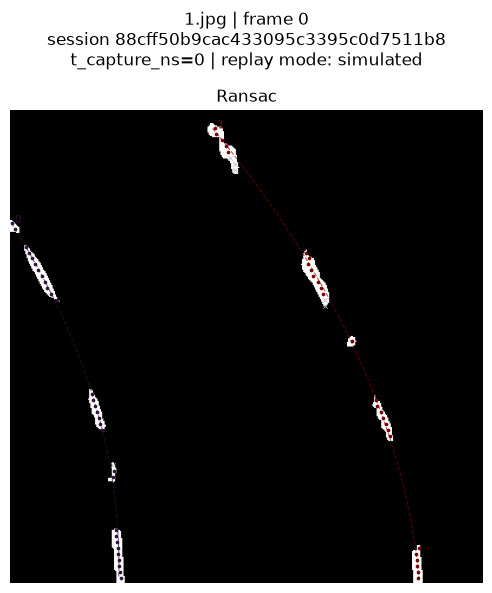

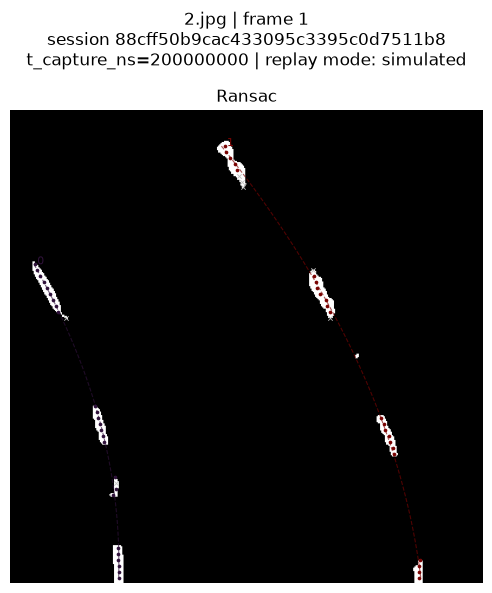

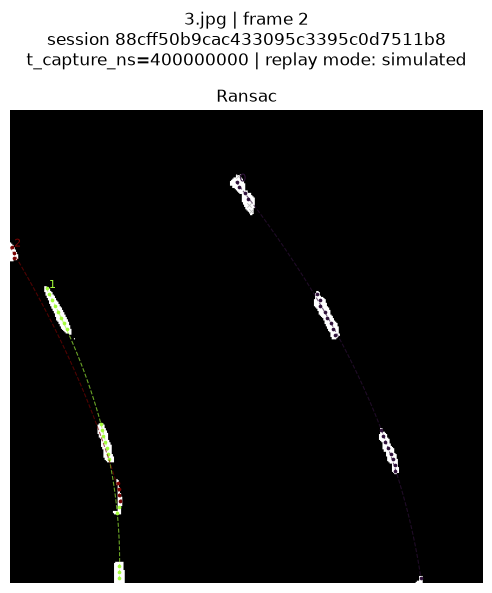

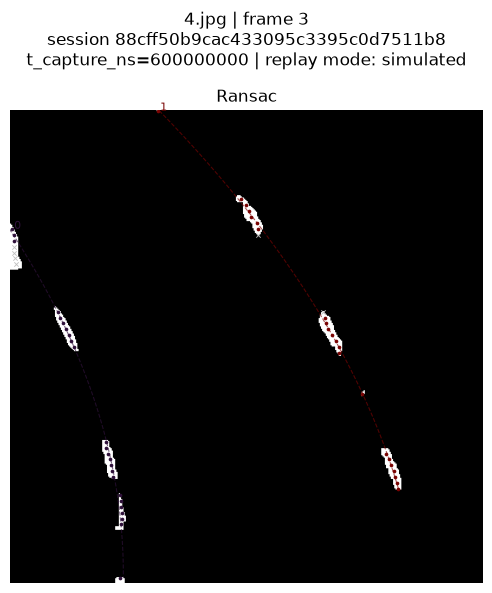

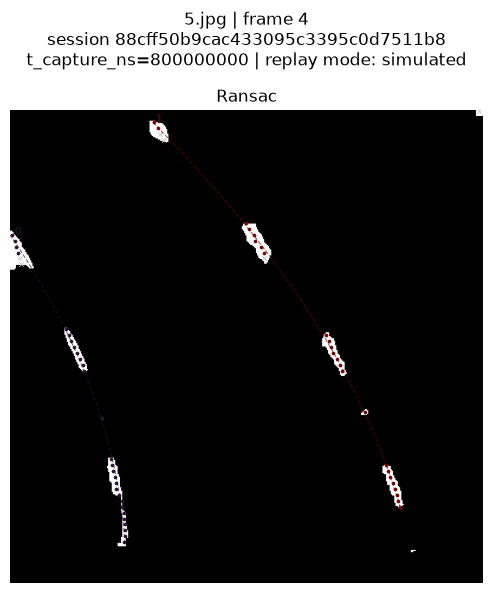

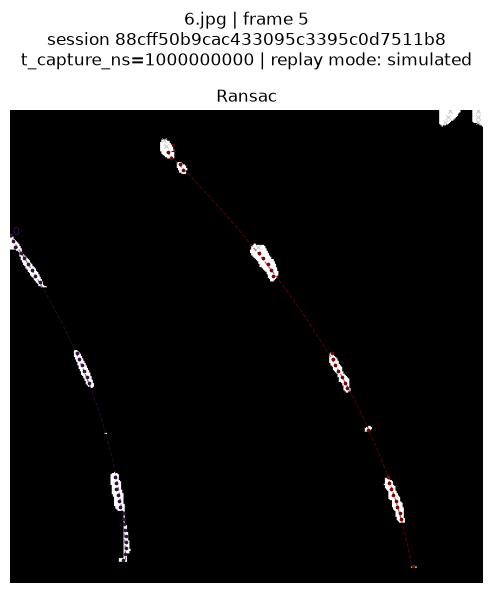

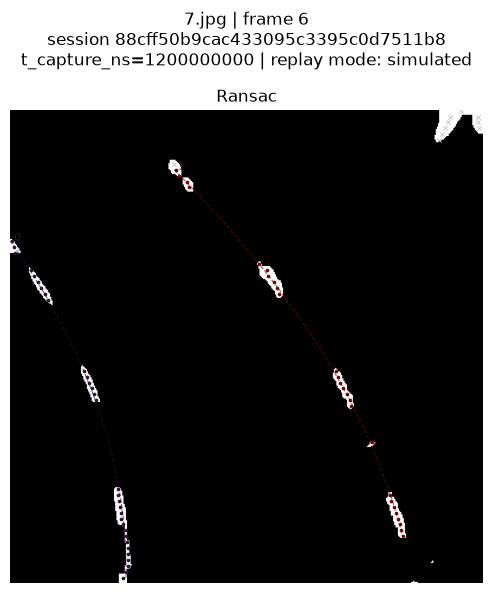

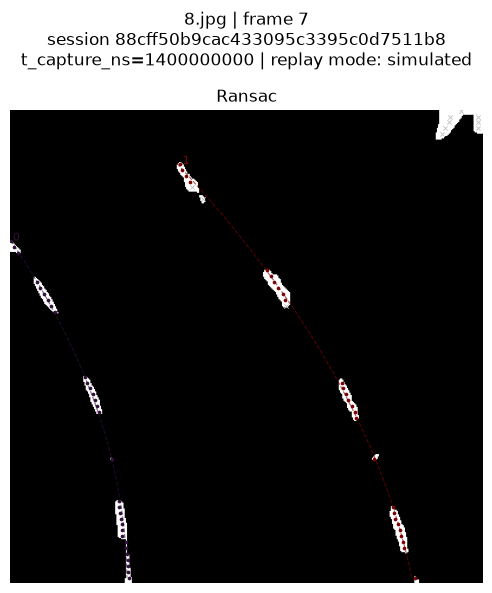

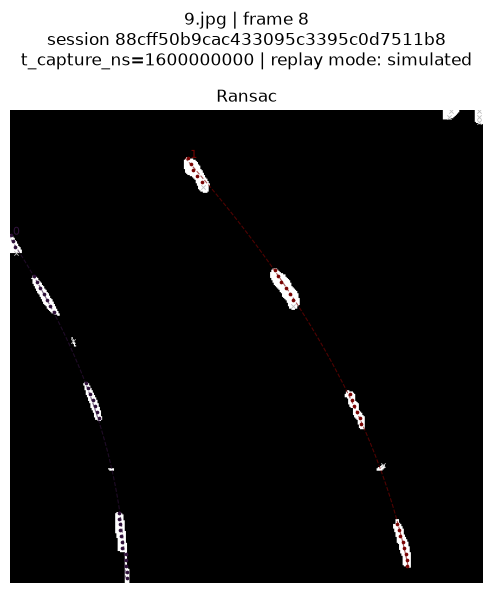

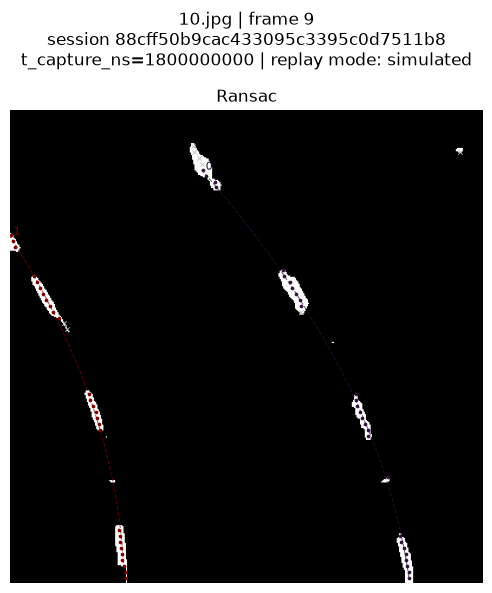

In [6]:
for display_frame in display_frames[:DISPLAY_LIMIT]:
    enabled_results = display_frame.get('baseline_results', {})
    if not enabled_results:
        continue
    fig, axes = plt.subplots(1, len(enabled_results), figsize=(6 * len(enabled_results), 6), squeeze=False)
    for ax, (method, baseline_result) in zip(axes[0], enabled_results.items()):
        ax.imshow(display_frame['binary_bev'], cmap='gray', vmin=0, vmax=1)
        comparison_candidates = baseline_result['candidates']
        colors = plt.get_cmap('turbo', max(1, len(comparison_candidates)))
        for candidate in comparison_candidates:
            points = candidate['observations']
            color = colors(candidate['candidate_id'])
            if method == 'ransac' and SHOW_RANSAC_MODEL:
                model_y = np.linspace(candidate['y_min'], candidate['y_max'], 100)
                model_x = np.polyval(candidate['model_coefficients'], (model_y-candidate['y_offset'])/candidate['y_scale'])
                ax.plot(model_x, model_y, linestyle='--', color=color, linewidth=0.8, alpha=0.65)
            elif method == 'continuity':
                for before, after in zip(points, points[1:]):
                    if after['y']-before['y'] <= ROW_SCAN_STEP:
                        ax.plot([before['x'],after['x']], [before['y'],after['y']], color=color, linewidth=0.7)
            elif method == 'fragment_linker_baseline' and SHOW_FRAGMENT_LINKS:
                by_id = {f['fragment_id']: f for f in display_frame['fragments']}
                for connection in candidate['links']:
                    before = by_id[connection['source_fragment_id']]['end_observation']
                    after = by_id[connection['target_fragment_id']]['start_observation']
                    ax.plot([before['x'],after['x']], [before['y'],after['y']], linestyle='--', color=color, linewidth=0.8)
            ax.scatter([point['x'] for point in points], [point['y'] for point in points], s=7, color=color, linewidths=0)
            ax.text(points[0]['x']+2, points[0]['y'], str(candidate['candidate_id']), color=color, fontsize=8)
        unassigned_points = baseline_result['unassigned']
        if unassigned_points:
            ax.scatter([point['x'] for point in unassigned_points], [point['y'] for point in unassigned_points], s=10, c='silver', marker='x', linewidths=0.6)
        ax.set_xlim(-0.5, display_frame['binary_bev'].shape[1]-0.5)
        ax.set_ylim(display_frame['binary_bev'].shape[0]-0.5, -0.5)
        ax.set_title(method.replace('_', ' ').title())
        ax.axis('off')
    fig.suptitle(display_frame['metadata_title'])
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## Phase 2.3.1 vs Phase 2.3.2 – Fragments and Linked Boundary Candidates

Compare the same cached frame side by side: individual fragments (F IDs) on the left and linked candidates (C IDs) on the right. Both panels use equally sized, aligned binary BEV canvases and preserve existing colors and original observed points. Optional dashed associations are inferred links, not paint. Metadata is shown once per figure; `DISPLAY_LIMIT`, figure closing and timing diagnostics are preserved. This display cell reruns no preprocessing or extraction.


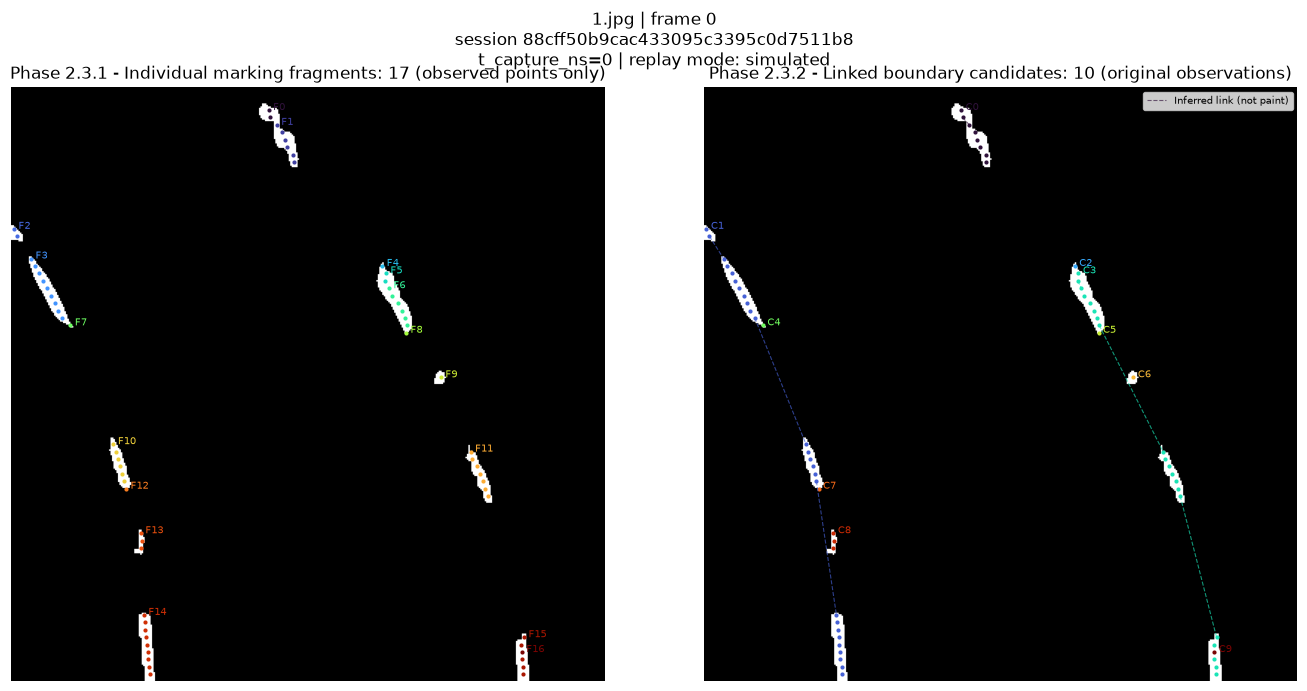

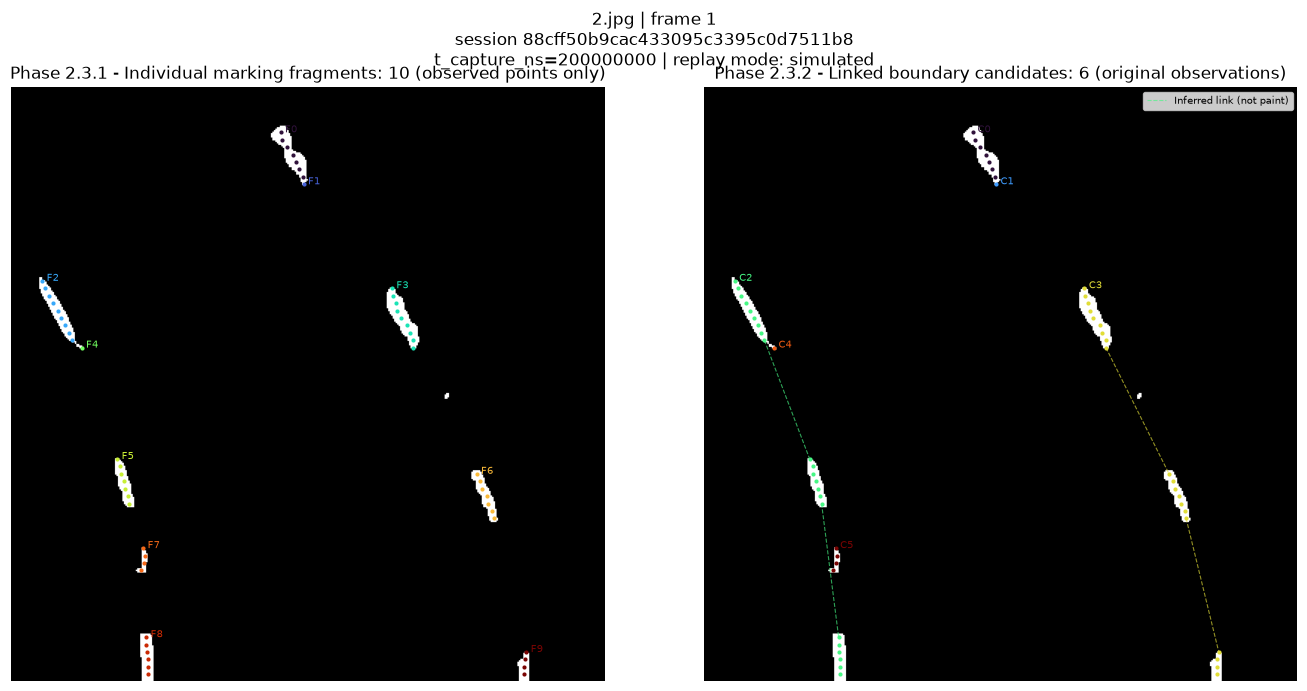

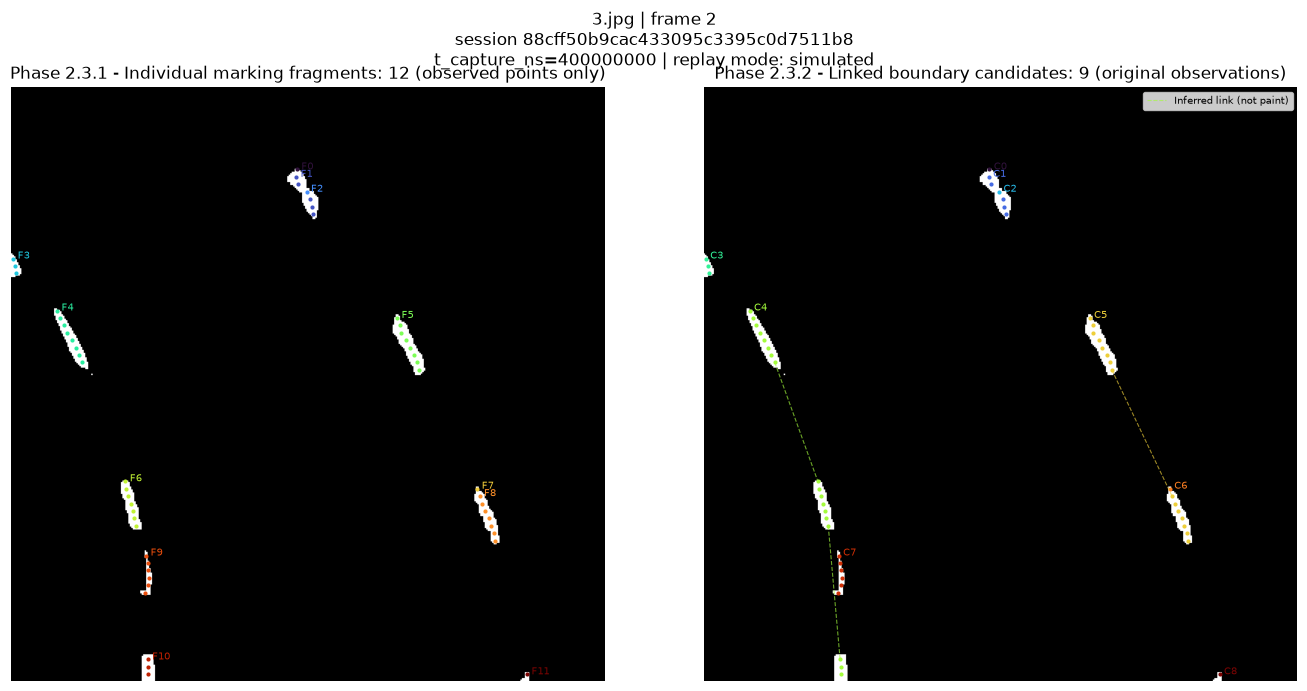

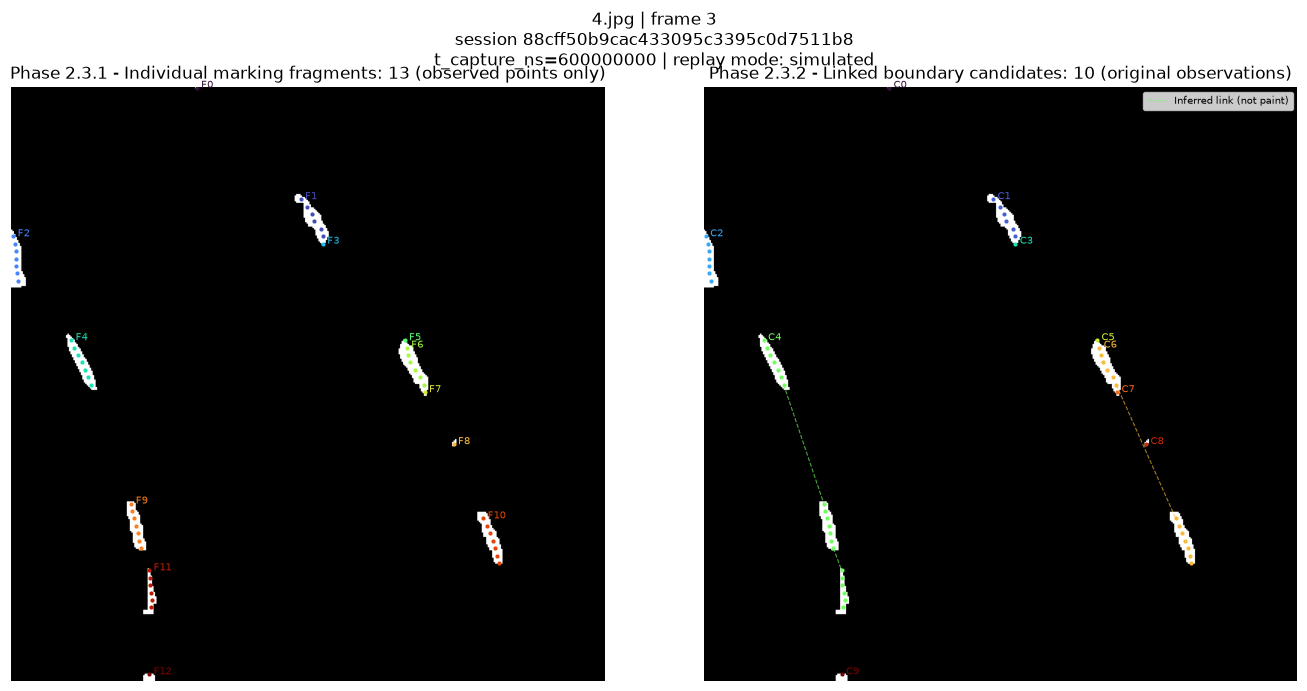

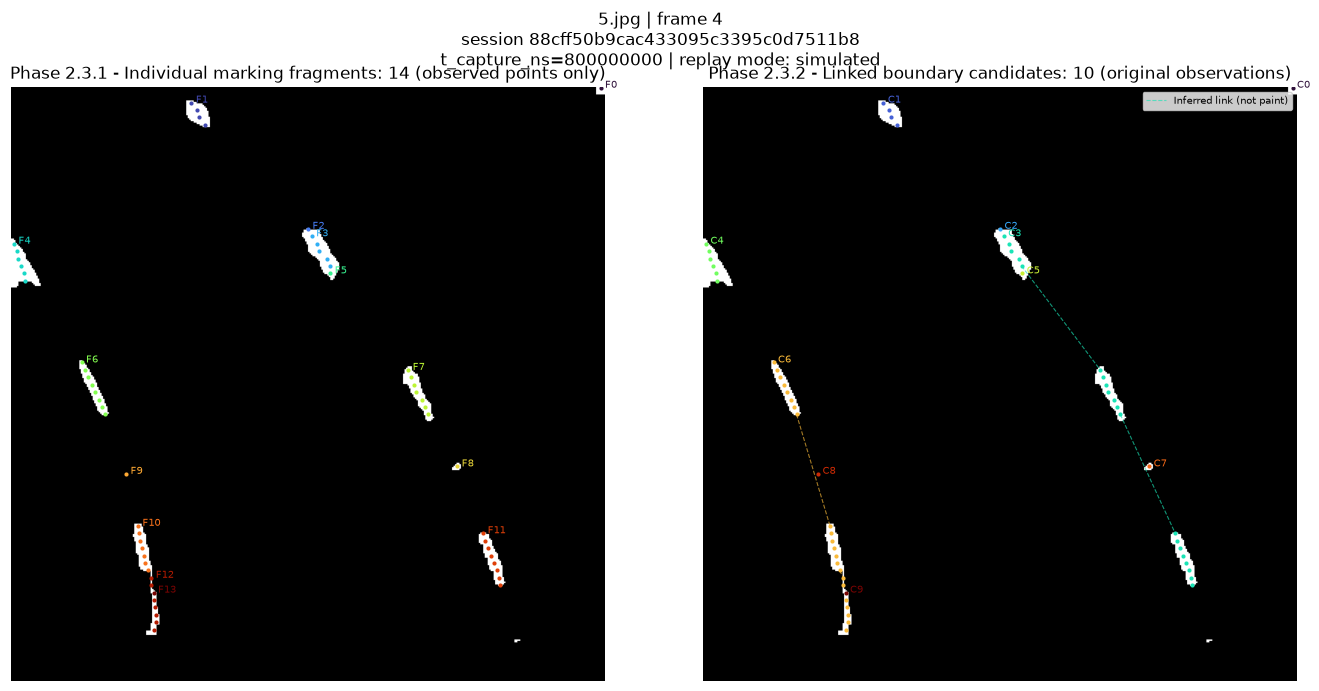

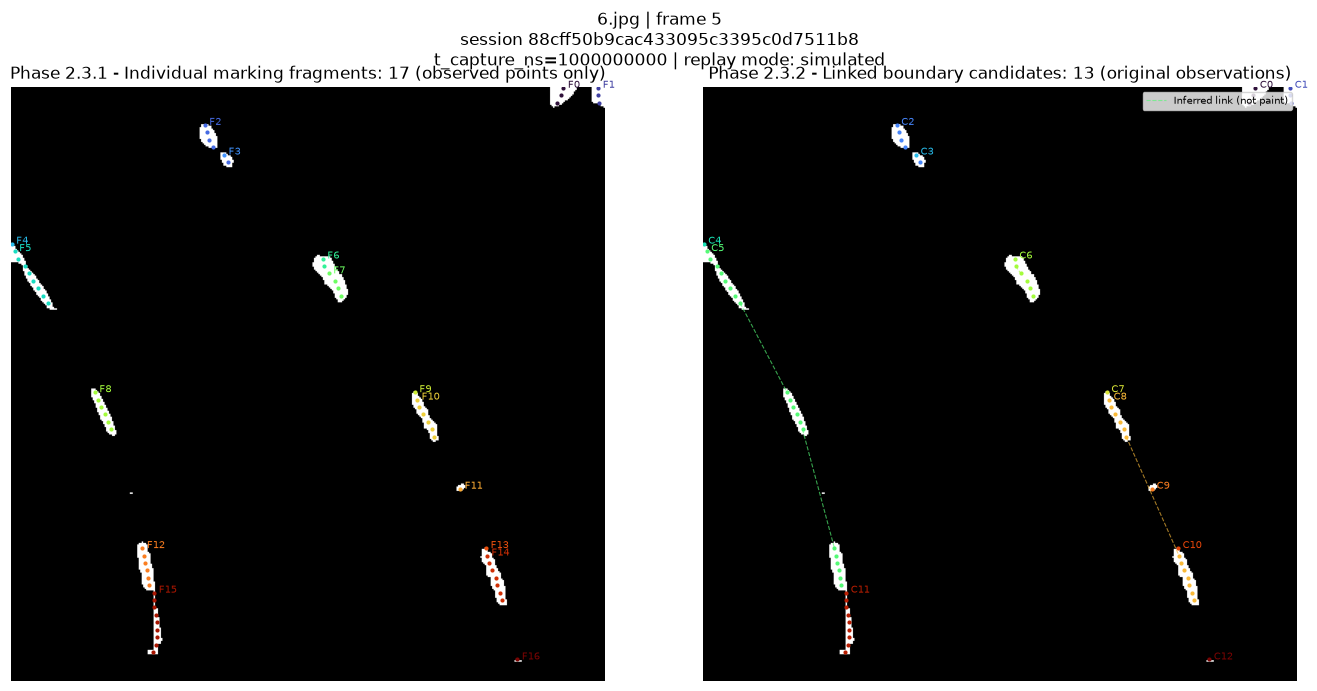

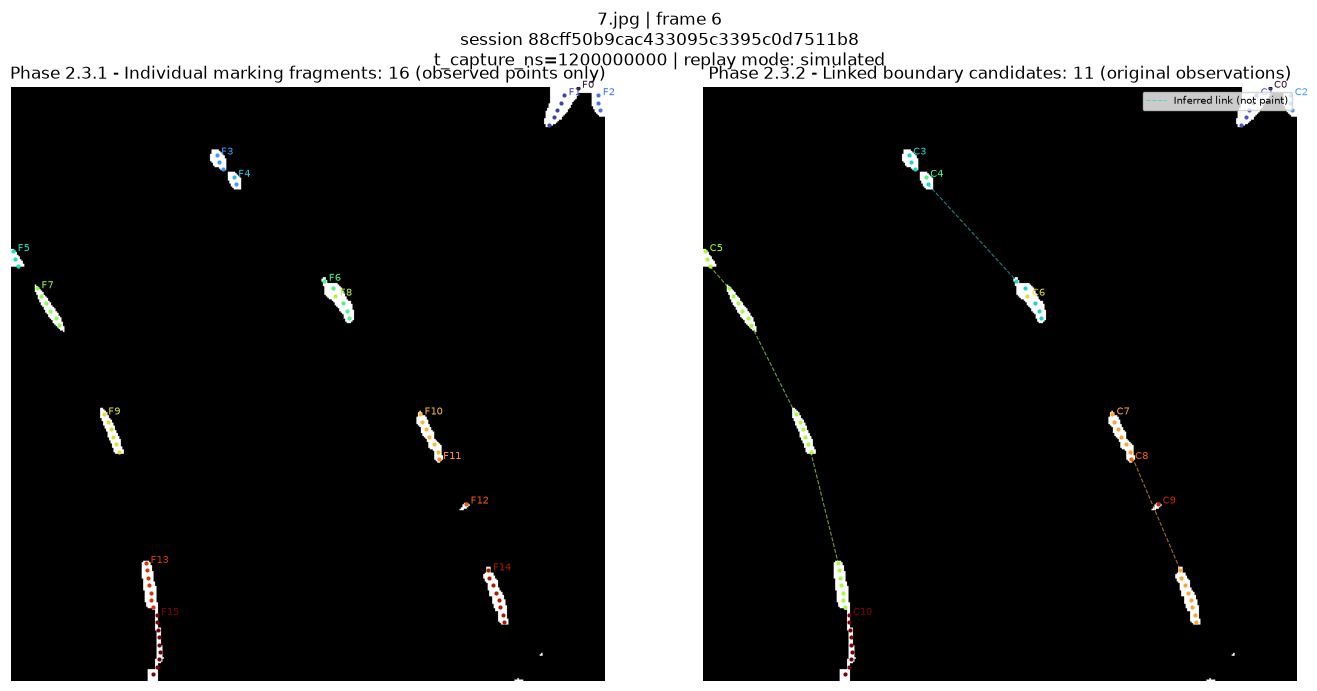

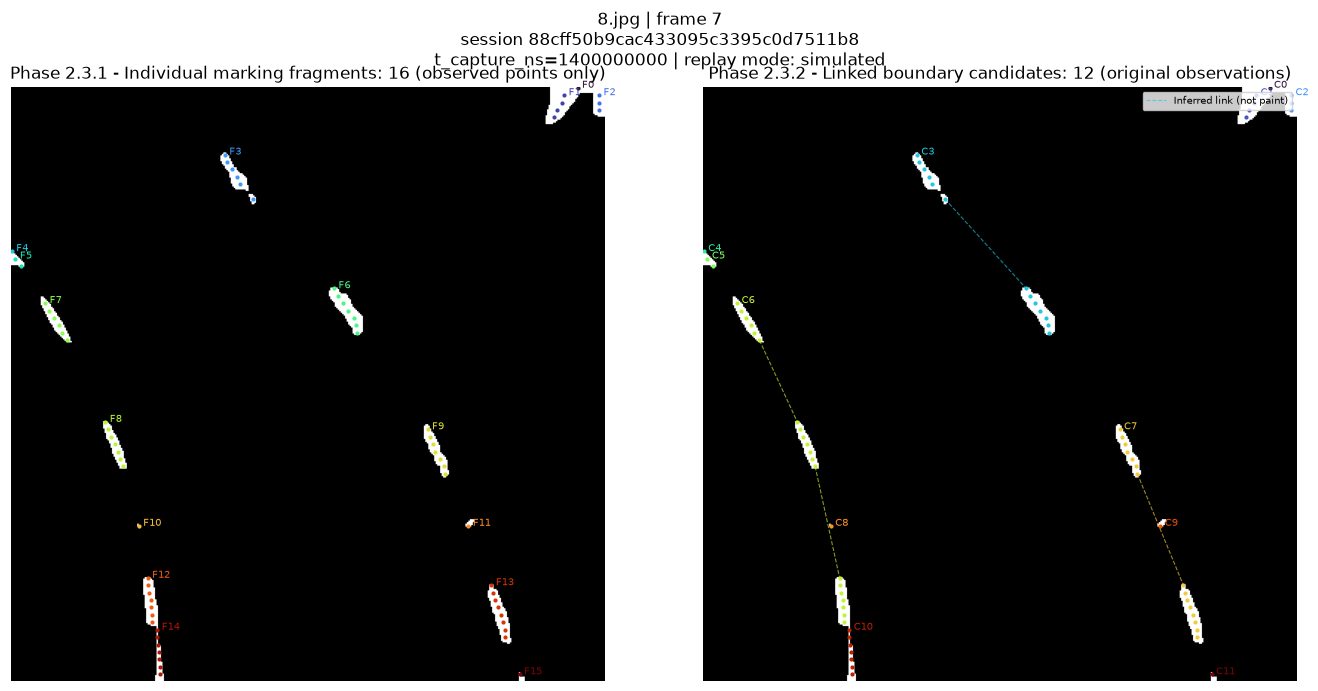

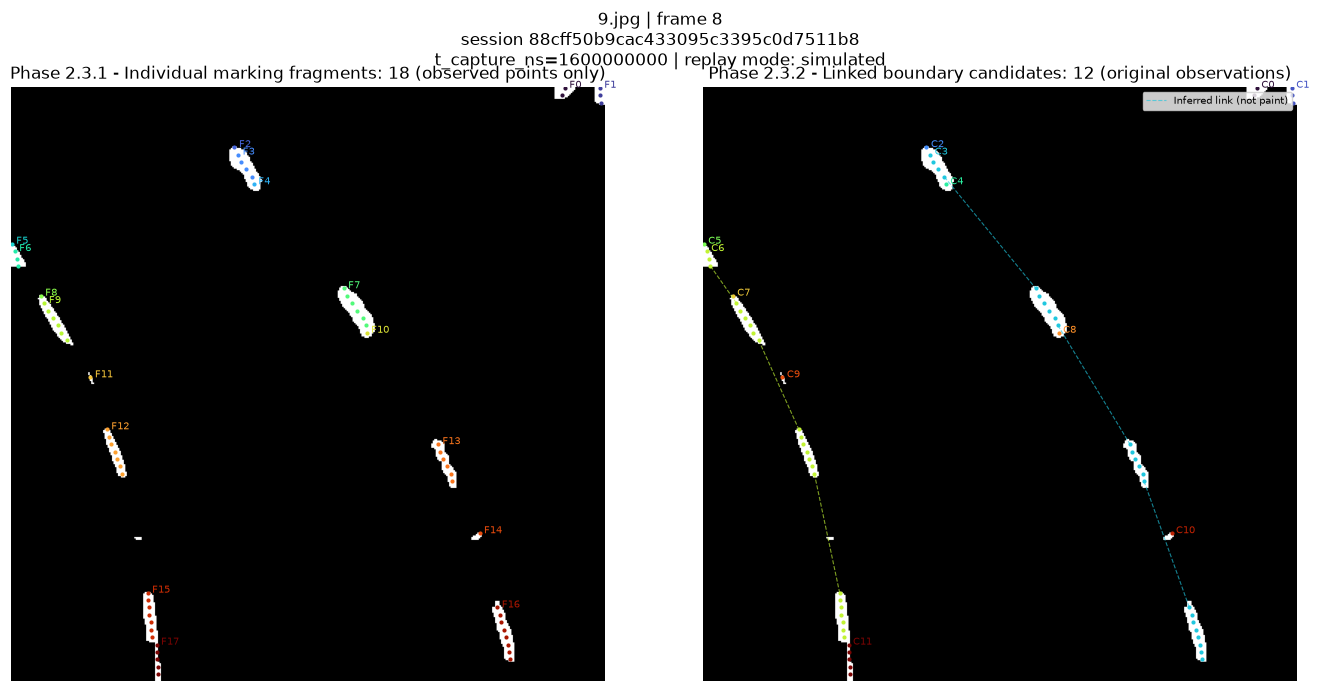

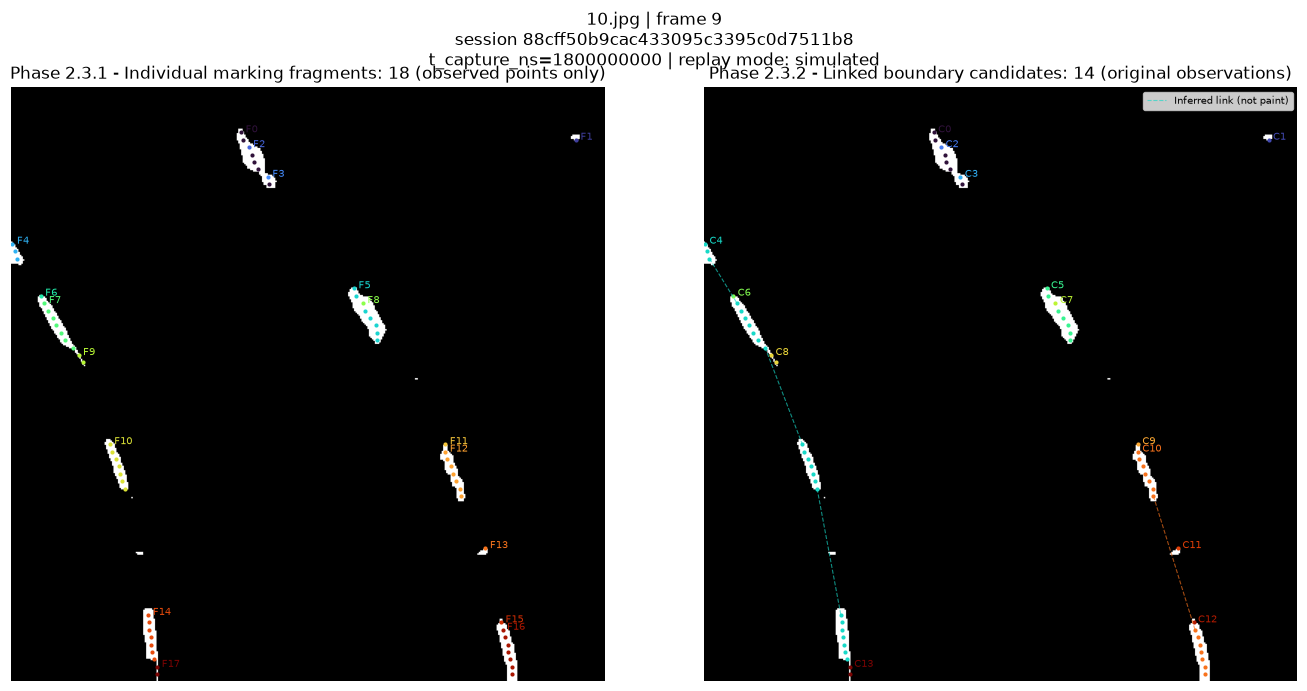

Fragment extraction: last 20 frames | median=0.359 ms | p95=0.541 ms | fragments/frame=10..18
Development-host extractor-call timings only, not Raspberry Pi benchmarks.


In [7]:
for fragment_frame in display_frames[:DISPLAY_LIMIT]:
    fragment_bev = fragment_frame['binary_bev']
    linking_bev = fragment_bev
    frame_fragments = fragment_frame['fragments']
    frame_candidates = fragment_frame['linked_candidates']
    fragments_by_id = {fragment['fragment_id']: fragment for fragment in frame_fragments}
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
    fragment_ax, linked_ax = axes
    fragment_ax.imshow(fragment_bev, cmap='gray', vmin=0, vmax=1)
    fragment_colors = plt.get_cmap('turbo', max(1, len(frame_fragments)))
    for fragment in frame_fragments:
        points = fragment['observations']
        color = fragment_colors(fragment['fragment_id'])
        fragment_ax.scatter([point['x'] for point in points], [point['y'] for point in points],
                   s=9, color=color, linewidths=0)
        fragment_ax.text(points[0]['x'] + 3, points[0]['y'],
                f"F{fragment['fragment_id']}", color=color, fontsize=7)
    fragment_ax.set_title(f'Phase 2.3.1 - Individual marking fragments: {len(frame_fragments)} (observed points only)')
    fragment_ax.axis('off')
    linked_ax.imshow(linking_bev, cmap='gray', vmin=0, vmax=1)
    linking_colors = plt.get_cmap('turbo', max(1, len(frame_candidates)))
    association_label_shown = False
    for candidate in frame_candidates:
        points = candidate['observations']
        color = linking_colors(candidate['candidate_id'])
        if SHOW_FRAGMENT_LINKS:
            for connection in candidate['links']:
                before = fragments_by_id[connection['source_fragment_id']]['end_observation']
                after = fragments_by_id[connection['target_fragment_id']]['start_observation']
                linked_ax.plot([before['x'], after['x']], [before['y'], after['y']],
                        linestyle='--', color=color, linewidth=0.8, alpha=0.65,
                        label=None if association_label_shown else 'Inferred link (not paint)')
                association_label_shown = True
        linked_ax.scatter([point['x'] for point in points], [point['y'] for point in points],
                   s=9, color=color, linewidths=0)
        linked_ax.text(points[0]['x'] + 3, points[0]['y'],
                f"C{candidate['candidate_id']}", color=color, fontsize=7)
    if association_label_shown:
        linked_ax.legend(loc='upper right', fontsize=7)
    linked_ax.set_title(f'Phase 2.3.2 - Linked boundary candidates: {len(frame_candidates)} (original observations)')
    linked_ax.axis('off')
    fragment_ax.set_aspect('equal')
    linked_ax.set_aspect('equal')
    fig.suptitle(fragment_frame['metadata_title'])
    fig.tight_layout()
    plt.show()
    plt.close(fig)

if fragment_diagnostics:
    fragment_times = [row['fragment_ms'] for row in fragment_diagnostics]
    fragment_counts = [row['fragment_count'] for row in fragment_diagnostics]
    print(f"Fragment extraction: last {len(fragment_times)} frames | "
          f"median={np.median(fragment_times):.3f} ms | p95={np.percentile(fragment_times, 95):.3f} ms | "
          f"fragments/frame={min(fragment_counts)}..{max(fragment_counts)}")
    print('Development-host extractor-call timings only, not Raspberry Pi benchmarks.')


## Phase 2.3.2 – Fragment Link Decision Diagnostics

Optional debugging only. Set `DEBUG_FRAGMENT_LINKING = True` before running the processing cell; records are cached only for frames within `DISPLAY_LIMIT`. This cell displays cached traces and never reruns a linker or upstream stage. Normal execution collects no diagnostic records or additional diagnostic metrics. Candidate outputs and thresholds are unchanged. Debug-enabled timings include trace collection and should not be compared with normal performance.

Expand a frame to inspect accepted connections and a bounded selection of nearby rejected pairs. `DEBUG_FRAME_IDS` can select specific frames, and the rejection display limit is adjustable. Records cover forward non-overlapping pairs in the normal Y window plus the nearest start row beyond it, so search-gap exclusions can be explained. Obviously distant pairs are omitted from the short report; all captured records are available in `display_frames[i]["fragment_link_debug"]["pairs"]`.

Checks show PASS/FAIL and whether the algorithm actually reached them. Comparisons after an earlier rejection are diagnostic-only, marked `[not reached]`; they never affect linking. Final reasons include support, gap, width, direction, lateral tolerance, ambiguity, occupied slots, observed/accepted crossings, and chain-fit residual or tangent disagreement.


In [8]:
if not DEBUG_FRAGMENT_LINKING:
    print('Fragment-link diagnostics disabled. Enable DEBUG_FRAGMENT_LINKING and rerun processing to record them.')
else:
    from html import escape
    from IPython.display import HTML, display

    for debug_frame in display_frames[:DISPLAY_LIMIT]:
        trace = debug_frame.get('fragment_link_debug')
        if trace is None:
            print('No cached trace: enable DEBUG_FRAGMENT_LINKING and rerun the processing cell once.')
            break
        if DEBUG_FRAME_IDS is not None and trace['frame_id'] not in DEBUG_FRAME_IDS:
            continue
        accepted_pairs = [pair for pair in trace['pairs'] if pair['status'] == 'accepted']
        rejected_pairs = [pair for pair in trace['pairs'] if pair['status'] == 'rejected']
        rejected_pairs.sort(key=lambda pair: (
            pair.get('cost') is None,
            not (pair['checks']['source_support']['passed'] and pair['checks']['target_support']['passed']),
            pair['display_distance'] / pair['lateral_tolerance_px'], pair['gap_px'],
            pair['source_fragment_id'], pair['target_fragment_id']))
        selected = accepted_pairs + rejected_pairs[:DEBUG_MAX_REJECTED_PAIRS_PER_FRAME]
        lines = [debug_frame['metadata_title'],
                 'PASS/FAIL = threshold comparison; [not reached] = not executed by the linker.',
                 'N/A = no valid tangent/metric; no tangent is invented.', '']
        for pair in selected:
            lines.append(f"F{pair['source_fragment_id']} -> F{pair['target_fragment_id']}")
            for name, check in pair['checks'].items():
                value = check.get('value')
                if 'value' not in check:
                    detail = ''
                else:
                    formatted = 'N/A' if value is None else (f'{value:.3f}' if isinstance(value, (float, np.floating)) else str(value))
                    limit_kind = 'min' if name in ('source_support', 'target_support') else 'limit'
                    detail = f" {formatted} ({limit_kind}={check.get('limit')})"
                passed = check['passed']
                verdict = 'N/A' if passed is None else ('PASS' if passed else 'FAIL')
                reached = '' if check['reached'] else ' [not reached]'
                lines.append(f"  {check['label']}:{detail}  {verdict}{reached}")
            if 'cost' in pair:
                lines.append(f"  Pair cost: {pair['cost']:.4f}")
            if pair.get('competing_pairs'):
                lines.append('  Alternatives: ' + ', '.join(
                    f"F{p['source_fragment_id']}->F{p['target_fragment_id']} cost={p['cost']:.4f}"
                    for p in pair['competing_pairs']))
            if 'chain_tangent_error_deg' in pair:
                lines.append(f"  Fit tangent error: {pair['chain_tangent_error_deg']:.3f} deg at F{pair['chain_tangent_fragment_id']}")
            lines.append(f"  {pair['status'].upper()}: {pair['reason']}")
            lines.append('')
        omitted = len(rejected_pairs) - min(len(rejected_pairs), DEBUG_MAX_REJECTED_PAIRS_PER_FRAME)
        lines.append(f'{omitted} other rejected pairs omitted; full records remain in the cached frame trace.')
        heading = (f"Frame {trace['frame_id']} | {trace['image_name']} | "
                   f"accepted={len(accepted_pairs)}, rejected shown={len(selected)-len(accepted_pairs)}")
        display(HTML('<details><summary>' + escape(heading) + '</summary><pre>' +
                     escape('\n'.join(lines)) + '</pre></details>'))


Fragment-link diagnostics disabled. Enable DEBUG_FRAGMENT_LINKING and rerun processing to record them.


## Candidate builder comparison — development host

Bounded, in-memory measurements of both builders on identical inputs. Candidate/support counts describe assignments, not correctness; visually inspect merges and splits before selecting a method.


In [9]:
if candidate_comparison:
    rows = list(candidate_comparison)
    counts = [row['observations'] for row in rows]
    print(f"Candidate comparison: last {len(rows)} frames on {platform.platform()}")
    print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | OpenCV {cv2.__version__}")
    print(f"Observations/frame: {min(counts)}..{max(counts)}, mean {np.mean(counts):.1f}")
    print('Development-computer timings only; not Raspberry Pi benchmarks.')
    print('Method       Median ms   P95 ms   Candidates/frame mean [range]   Assigned/frame mean [range]')
    for method in ('continuity', 'ransac', 'fragment_linker_baseline', 'fragment_linking'):
        if not all(f'{method}_ms' in row for row in rows):
            continue
        times = [row[f'{method}_ms'] for row in rows]
        accepted = [row[f'{method}_candidates'] for row in rows]
        assigned_counts = [row[f'{method}_assigned'] for row in rows]
        print(f"{method:16} {np.median(times):9.3f} {np.percentile(times, 95):8.3f}   "
              f"{np.mean(accepted):5.1f} [{min(accepted)}..{max(accepted)}]                 "
              f"{np.mean(assigned_counts):5.1f} [{min(assigned_counts)}..{max(assigned_counts)}]")
else:
    print('No candidate comparison samples.')


Candidate comparison: last 20 frames on Windows-11-10.0.26200-SP0
Python 3.12.10 | NumPy 2.5.4 | OpenCV 5.0.0
Observations/frame: 51..80, mean 64.4
Development-computer timings only; not Raspberry Pi benchmarks.
Method       Median ms   P95 ms   Candidates/frame mean [range]   Assigned/frame mean [range]
ransac              25.976   38.178     2.3 [2..4]                  57.7 [46..80]
fragment_linking     0.623    0.978    10.3 [6..14]                  64.4 [51..80]


## Host timing diagnostics

Median and p95 are reported after at least five samples. These are measurements on the current development computer, **not Raspberry Pi camera latency**. Replay reports host queue/decode/preprocessing durations only: recorded/simulated capture clocks are never subtracted from this computer's monotonic clock. Live results additionally support capture-to-publish, publish-to-receive and estimated frame-age metrics.

In [10]:
summary = timing.summary()
print('Host monotonic clock resolution (ns):', summary['host_clock_resolution_ns'])
print('Zero measured durations can mean work is below this clock resolution.')
if not summary['ready']:
    print(f"Insufficient timing samples: {summary['samples']}/{summary['required_samples']}")
else:
    print('Replay host processing timings (milliseconds), not Raspberry Pi performance:')
    for metric, values in summary['metrics_ms'].items():
        print(f"{metric}: median={values['median']:.3f}, p95={values['p95']:.3f}, n={values['samples']}")

Host monotonic clock resolution (ns): 15625000
Zero measured durations can mean work is below this clock resolution.
Replay host processing timings (milliseconds), not Raspberry Pi performance:
preprocessing: median=0.000, p95=0.800, n=20
processing_including_decode: median=0.000, p95=16.000, n=20
wait_before_processing: median=0.000, p95=0.000, n=20


## Recorded metadata format

Use a JSONL record per line, a JSON array of records, or a JSON object containing a `frames` list. Example record:

```json
{"image_path":"frame0001.jpg","session_id":"original-pi-session","frame_id":125,"t_capture_ns":583204510000,"t_publish_ns":583205000000}
```

Image paths may be absolute or relative to IMAGE_DIRECTORY (or the manifest directory). Records require only identity/capture metadata and an image path; no replay-specific packet field is required. Timing mode belongs to this notebook, not production. The notebook passes only current-host stage timestamps to latency summaries, excluding recorded/simulated capture and original publish clocks. Recorded timestamps and identities are not rewritten, and malformed/out-of-order rows raise a clear error. For missing original metadata, use simulated mode instead of inventing recorded times.

A live session UUID changes after camera restart; frame counters may then restart at zero. Recorded camera timestamps from another boot/machine are a separate clock domain. A complete recorder and MCU/IMU synchronization are outside this phase.

## Phase 2.3.2 scope

The latest observations, baseline candidates, visible fragments, and `linked_candidates` are per-frame results. Existing baselines, fragment extraction, adaptation, replay, metadata and live runtime are unchanged. This stage adds deterministic fragment chaining only, preserving every real observation. No RANSAC fallback, temporal state, lane pairing, left/right identities, vehicle motion, confidence state machine, sensor integration or control is implemented. Stop here for candidate review.
